# 05 — Predictive Analytics: Return Ratio Regression (`return_ratio`)

## Tujuan
1. Memvalidasi pembagian data berbasis waktu (*temporal split*: Latih `<= 2018-06-30`, Validasi `2018-07-01` s.d. `2019-06-30`, Uji `>= 2019-07-01`) pada populasi pinjaman yang hasil akhirnya telah diketahui (`is_resolved == True`, `n = 113.560`), serta mendokumentasikan karakteristik pergeseran distribusi `return_ratio` akibat perbedaan umur pengamatan kohort.
2. Melatih dan membandingkan model regresi linear terstandarisasi (`Ridge-A`) serta *Gradient Boosted Decision Trees* dengan fungsi rugi kuadrat (`LGBM-Reg-L2`) vs fungsi rugi tangguh terhadap pencilan (`LGBM-Reg-Huber`) menggunakan **Set A** (`36` fitur stabil saat pengajuan) terhadap tiga pembanding naif (`Median Global`, `Median per Rating`, `Median per Country × Rating`) dan `ExpectedReturn` Bondora.
3. Mengevaluasi metrik keseluruhan (`MAE`, `RMSE`, $R^2$, korelasi peringkat Spearman $ho_s$), membedah kesalahan prediksi secara terpisah pada kelompok pinjaman **gagal bayar (`default == 1`)** vs **lunas (`default == 0`)**, menganalisis *lift* 10 desil, serta menginterpretasikan 15 fitur penggerak utama menggunakan `SHAP`.

## Input / Output
- **Input:**
  - Dataset bersih: `data/processed/bondora_clean.parquet` (`113.560` baris `is_resolved == True`).
  - Artefak hasil `python -m src.models.train`: `models/lgbm_return_ratio_setA.joblib`, `models/ridge_return_ratio_setA.joblib`, `data/processed/predictions_return_ratio.parquet`, tabel `reports/tables/05_*.csv`, dan grafik `reports/figures/05_*.png`.
- **Output:**
  - Pemeriksaan nilai antara, evaluasi komparatif regresi, analisis residual per segmen, tabel *lift* per desil, SHAP regresi, dan sintesis implikasi untuk **Tahap 5 (Prescriptive Analytics)**.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import src.config as config

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 140)

with open(config.MODELS_DIR / "train_metadata.json", "r", encoding="utf-8") as f:
    train_meta = json.load(f)

print(f"Project root                : {config.PROJECT_ROOT}")
print(f"Model utama regresi terpilih: {train_meta['regression']['primary_regression_model']}")
print(f"Waktu eksekusi regresi      : {train_meta['regression']['elapsed_seconds']:.2f} detik")
print(f"Val MAE LGBM-Huber vs L2    : {train_meta['regression']['val_mae_lgbm_huber']:.4f} vs {train_meta['regression']['val_mae_lgbm_l2']:.4f} (Ridge: {train_meta['regression']['val_mae_ridge']:.4f})")

Project root                : C:\Tugas-3-Pemodelan-Data\bondora-analytics
Model utama regresi terpilih: LGBM-Reg-Huber
Waktu eksekusi regresi      : 75.79 detik
Val MAE LGBM-Huber vs L2    : 0.3640 vs 0.3653 (Ridge: 0.3858)


## 1. Pembagian Waktu Populasi Resolved & Karakteristik Target (`05_split_summary.csv`)

Populasi regresi mencakup seluruh `113.560` pinjaman dengan `is_resolved == True` dan `return_ratio` valid:
- **Latih (`train`, `<= 2018-06-30`):** `54.103` baris (`mean = 0,9136`, `median = 1,0366`, default rate lifetime `60,36%`)
- **Validasi (`val`, `2018-07-01..2019-06-30`):** `24.782` baris (`mean = 0,6720`, `median = 0,5774`, default rate lifetime `67,97%`)
- **Uji (`test`, `>= 2019-07-01`):** `34.675` baris (`mean = 0,5708`, `median = 0,3917`, default rate lifetime `64,49%`)

> **Peringatan Bias Seleksi Populasi *Resolved*:** Pinjaman dari kohort terbaru (`>= Juli 2019`) yang sudah berstatus *resolved* pada tanggal laporan (`2021-07-20`) hanya terdiri atas pinjaman yang lunas lebih cepat atau gagal bayar dini, dan memiliki waktu pemulihan penagihan (*recovery*) yang jauh lebih singkat dibanding kohort `<= 2018`. Pergeseran struktural ini menyebabkan rata-rata aktual `return_ratio` pada data uji lebih rendah daripada data latih.

In [2]:
split_reg_df = pd.read_csv(config.TABLES_DIR / "05_split_summary.csv")
display(split_reg_df)

assert int(split_reg_df.loc[split_reg_df["split"].isin(["train", "val", "test"]), "n"].sum()) == 113_560
assert int(split_reg_df.loc[split_reg_df["split"].isin(["train", "val", "test"]), "n_default_lifetime"].sum()) == 71_864

,split,deskripsi,n,proporsi_populasi,n_default_lifetime,default_rate_lifetime,mean_return_ratio,std_return_ratio,p25_return_ratio,median_return_ratio,p75_return_ratio,loan_date_min,loan_date_max
0,train,Latih Resolved (<= 2018-06-30),54103,0.476427,32656,0.603589,0.913647,0.556683,0.451224,1.036649,1.266695,2009-02-28,2018-06-30
1,val,Validasi Resolved (> 2018-06-30 s.d. 2019-06-30),24782,0.218228,16845,0.679727,0.671976,0.468574,0.261894,0.577350,1.077131,2018-07-01,2019-06-30
2,test,Uji Resolved (> 2019-06-30),34675,0.305345,22363,0.644932,0.570775,0.460345,0.151063,0.391706,1.040463,2019-07-01,2021-07-18
3,Total,Seluruh Populasi Resolved (is_resolved == True),113560,1.000000,71864,0.632828,0.756213,0.533028,0.253263,0.797424,1.147674,2009-02-28,2021-07-18


## 2. Evaluasi Model Regresi & Pembanding (`05_metrics_regression.csv`)

Pada data validasi dan uji, tiga keluarga model pada **Set A (`36` fitur)** dibandingkan terhadap empat pembanding:
1. **`BASE-Med-Global`:** menebak median data latih (`1,0366`) untuk semua pinjaman (MAE uji `0,5323`, $R^2 = -1,0242$).
2. **`BASE-Med-Rating`:** menebak median data latih per kelas `Rating` (MAE uji `0,5043`, $R^2 = -0,7638$, Spearman $ho_s = 0,2034$).
3. **`BASE-Med-CountryRating`:** menebak median data latih per kombinasi `Country × Rating` (MAE uji `0,4697`, $R^2 = -0,4868$, Spearman $ho_s = 0,1925$).
4. **`BASE-ExpectedReturn`:** menggunakan kolom `ExpectedReturn` Bondora sebagai skor pembanding pada data uji ($ho_s = -0,1651$, berkorelasi negatif karena pinjaman berbunga tinggi dan `ExpectedReturn` tinggi di kohort baru mengalami gagal bayar dini yang tinggi).
5. **`Ridge-A`:** regresi linear terstandarisasi ($lpha = 0,1$; MAE uji `0,4159`, RMSE `0,4762`, Spearman $ho_s = 0,2301$).
6. **`LGBM-Reg-L2` vs `LGBM-Reg-Huber`:** `LGBM-Reg-Huber` terpilih pada validasi (MAE validasi `0,3640` vs `0,3653`) dan mencapai kinerja terbaik pada data uji (**MAE `0,3902`**, **RMSE `0,4545`**, **$R^2 = 0,0252`**, **Spearman $ho_s = 0,2881$**; sedangkan `LGBM-Reg-L2` mencapai MAE `0,3934` dan Spearman $ho_s = 0,2921$).
7. **Bias Level Prediksi Regresi pada Data Uji (Gunakan sebagai Urutan):** Rata-rata prediksi `LGBM-Reg-Huber` pada data uji adalah **`0,6746` vs rata-rata aktual `0,5708`** (selisih **`+0,1038`**; pada validasi `0,8034` vs aktual `0,6720`). Sejalan dengan model klasifikasi, **level prediksi regresi cenderung terlalu tinggi pada kohort uji**, sehingga **`pred_return_ratio` harus digunakan sebagai urutan (*ranking*) kualitas pengembalian, bukan sebagai estimasi pengembalian absolut**.

=== Tabel Metrik Regresi pada Data Validasi dan Data Uji ===


,kode_model,nama_model,split,n,mae,rmse,r2,spearman_rho,spearman_p_value,mean_actual,mean_predicted,mean_actual_decile1_tertinggi,mean_actual_decile10_terendah,selisih_decile1_minus_decile10,mae_default,rmse_default,mean_actual_default,mean_pred_default,mae_non_default,rmse_non_default,mean_actual_non_default,mean_pred_non_default
0,BASE-Med-Global,Median Global Data Latih,val,24782,0.492529,0.593750,-0.605715,0.000000,1.000000e+00,0.671976,1.036649,0.753376,0.602720,0.150656,0.637404,0.694435,0.416780,1.036649,0.185056,0.277978,1.213588,1.036649
1,BASE-Med-Rating,Median per Rating (Data Latih),val,24782,0.465894,0.556295,-0.409519,0.136037,1.142780e-102,0.671976,0.968233,0.754923,0.594413,0.160510,0.574659,0.633534,0.416780,0.957603,0.235059,0.338260,1.213588,0.990794
2,BASE-Med-CountryRating,Median per Country x Rating (Data Latih),val,24782,0.438627,0.529750,-0.278209,0.158576,2.910333e-139,0.671976,0.872307,0.770604,0.629419,0.141185,0.500181,0.566699,0.416780,0.846827,0.307988,0.441193,1.213588,0.926383
3,Ridge-A,Ridge Regression (Set A),val,24782,0.385816,0.466255,0.009837,0.254590,0.000000e+00,0.671976,0.687733,0.910320,0.514240,0.396080,0.350097,0.416997,0.416780,0.654828,0.461625,0.556534,1.213588,0.757568
4,LGBM-Reg-L2,LightGBM Regressor L2 (Set A),val,24782,0.365288,0.445791,0.094846,0.347851,0.000000e+00,0.671976,0.677647,0.983286,0.446778,0.536508,0.326723,0.391885,0.416780,0.633079,0.447137,0.542737,1.213588,0.772237
5,LGBM-Reg-Huber,LightGBM Regressor Huber (Set A),val,24782,0.364025,0.448282,0.084700,0.343979,0.000000e+00,0.671976,0.662009,0.981285,0.456418,0.524867,0.318930,0.385932,0.416780,0.615577,0.459731,0.557985,1.213588,0.760554
6,BASE-Med-Global,Median Global Data Latih,test,34675,0.532272,0.654943,-1.024195,0.000000,1.000000e+00,0.570775,1.036649,0.530490,0.832206,-0.301716,0.771928,0.807521,0.268357,1.036649,0.096970,0.153789,1.120074,1.036649
7,BASE-Med-Rating,Median per Rating (Data Latih),test,34675,0.504261,0.611360,-0.763755,0.203376,0.000000e+00,0.570775,0.982209,0.642050,0.419560,0.222490,0.707206,0.746611,0.268357,0.967364,0.135641,0.200386,1.120074,1.009172
8,BASE-Med-CountryRating,Median per Country x Rating (Data Latih),test,34675,0.469714,0.561318,-0.486833,0.192539,8.453490e-287,0.570775,0.899425,0.720074,0.456888,0.263186,0.618369,0.667911,0.268357,0.868533,0.199704,0.277642,1.120074,0.955536
9,BASE-ExpectedReturn,ExpectedReturn Bondora (Skor Benchmark),test_irisan_er,34675,0.475662,0.637080,-0.915285,-0.165131,1.803136e-210,0.570775,0.138517,0.469537,0.704607,-0.235070,0.189983,0.277270,0.268357,0.145675,0.994557,1.001719,1.120074,0.125517



Bias Level Regresi Uji (LGBM-Reg-Huber): rata-rata prediksi = 0.6746 vs aktual = 0.5708 (selisih +0.1038) -> gunakan sebagai urutan (Spearman rho = 0.2881)

=== Perbandingan Error Terpisah: Pinjaman Default (default=1) vs Non-Default (default=0) pada Data Uji ===


,kode_model,mae,rmse,r2,spearman_rho,mae_default,mean_actual_default,mean_pred_default,mae_non_default,mean_actual_non_default,mean_pred_non_default
6,BASE-Med-Global,0.532272,0.654943,-1.024195,0.000000,0.771928,0.268357,1.036649,0.096970,1.120074,1.036649
7,BASE-Med-Rating,0.504261,0.611360,-0.763755,0.203376,0.707206,0.268357,0.967364,0.135641,1.120074,1.009172
8,BASE-Med-CountryRating,0.469714,0.561318,-0.486833,0.192539,0.618369,0.268357,0.868533,0.199704,1.120074,0.955536
9,BASE-ExpectedReturn,0.475662,0.637080,-0.915285,-0.165131,0.189983,0.268357,0.145675,0.994557,1.120074,0.125517
10,Ridge-A,0.415896,0.476235,-0.070256,0.230094,0.453265,0.268357,0.688952,0.348022,1.120074,0.779864
11,LGBM-Reg-L2,0.393375,0.455851,0.019402,0.292074,0.411930,0.268357,0.639182,0.359671,1.120074,0.770455
12,LGBM-Reg-Huber,0.390219,0.454496,0.025223,0.288103,0.402613,0.268357,0.625284,0.367706,1.120074,0.764065


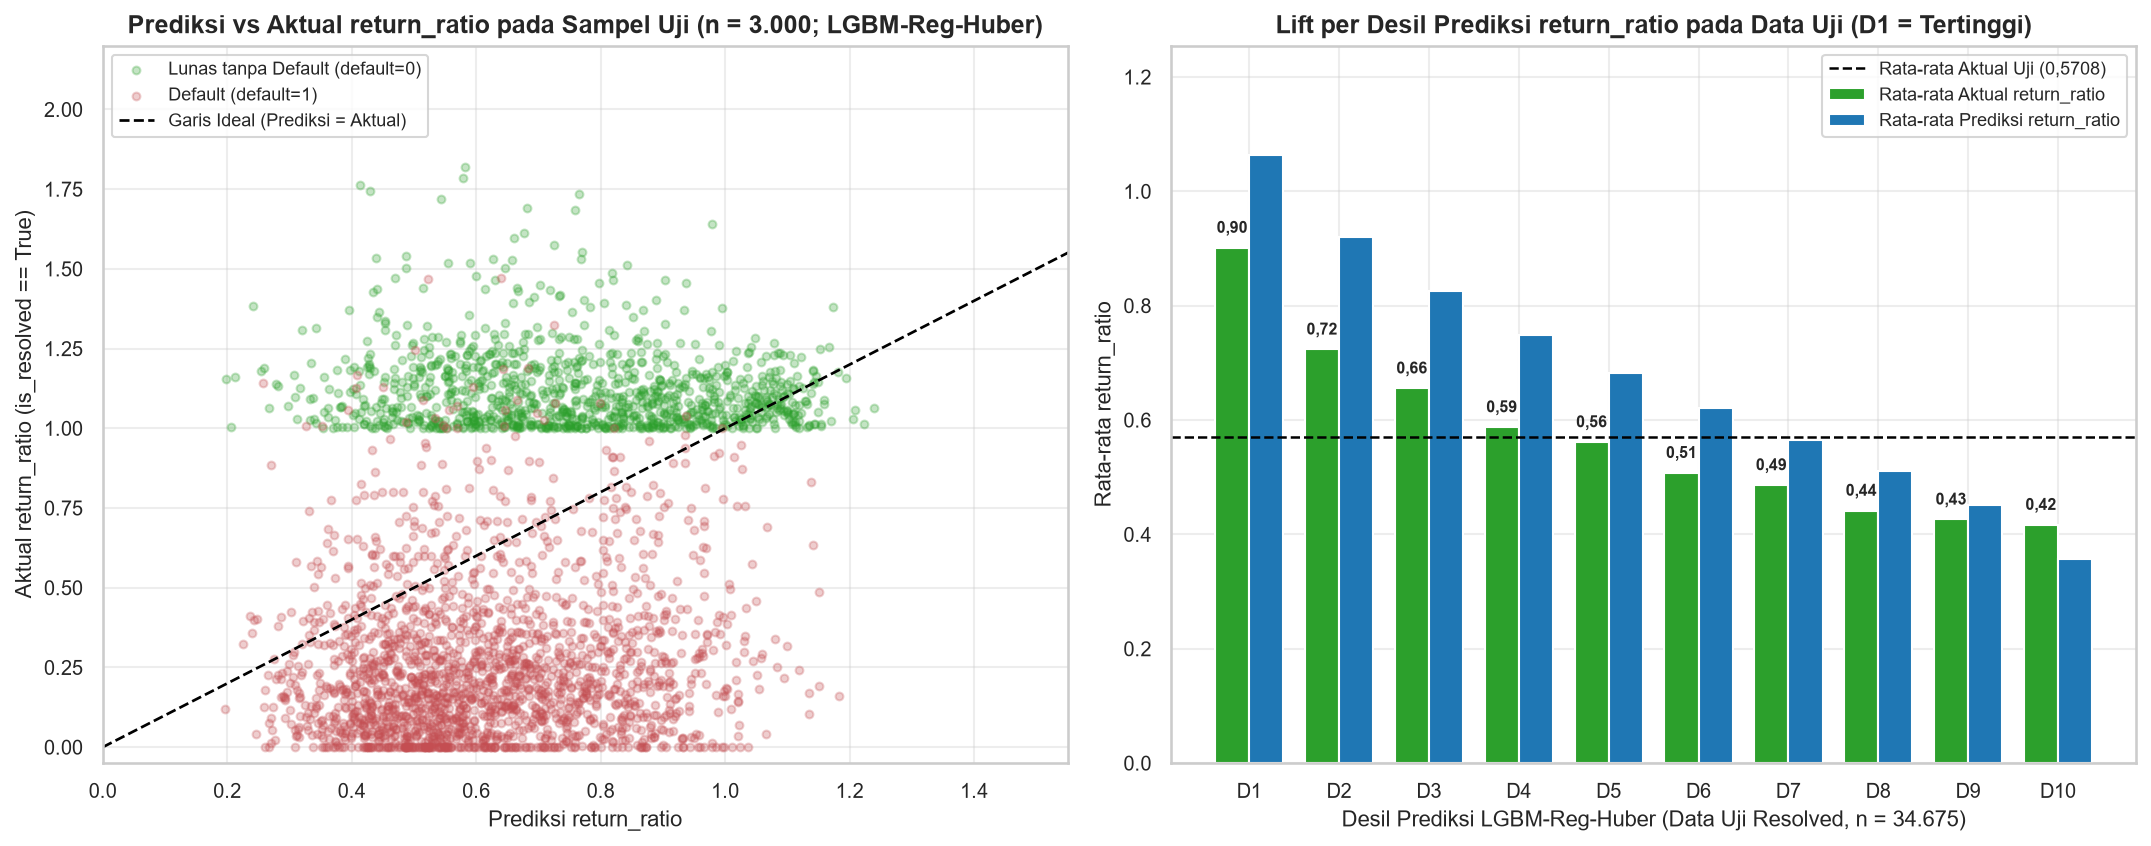

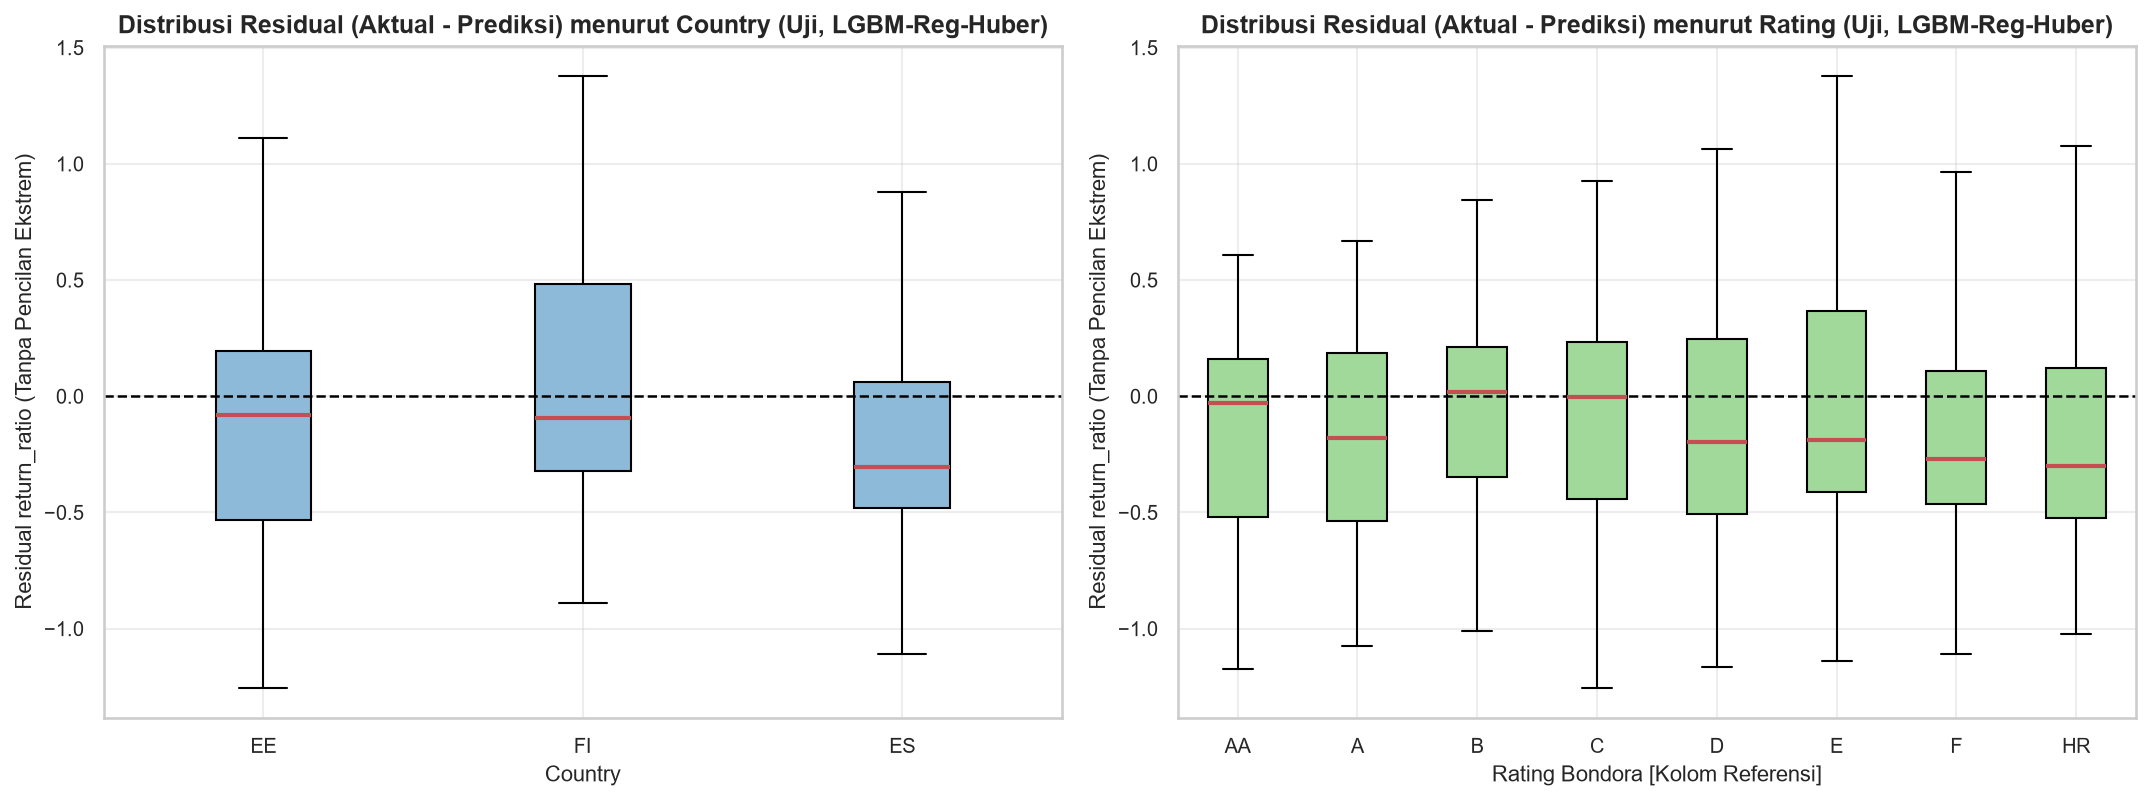

In [3]:
metrics_reg_df = pd.read_csv(config.TABLES_DIR / "05_metrics_regression.csv")
print("=== Tabel Metrik Regresi pada Data Validasi dan Data Uji ===")
display(metrics_reg_df)

row_huber_test = metrics_reg_df.loc[(metrics_reg_df["kode_model"] == "LGBM-Reg-Huber") & (metrics_reg_df["split"] == "test")].iloc[0]
print(f"\nBias Level Regresi Uji (LGBM-Reg-Huber): rata-rata prediksi = {row_huber_test['mean_predicted']:.4f} vs aktual = {row_huber_test['mean_actual']:.4f} "
      f"(selisih {row_huber_test['mean_predicted'] - row_huber_test['mean_actual']:+.4f}) -> gunakan sebagai urutan (Spearman rho = {row_huber_test['spearman_rho']:.4f})")

print("\n=== Perbandingan Error Terpisah: Pinjaman Default (default=1) vs Non-Default (default=0) pada Data Uji ===")
test_reg_sub = metrics_reg_df.loc[metrics_reg_df["split"].str.startswith("test"), [
    "kode_model", "mae", "rmse", "r2", "spearman_rho",
    "mae_default", "mean_actual_default", "mean_pred_default",
    "mae_non_default", "mean_actual_non_default", "mean_pred_non_default"
]]
display(test_reg_sub)

display(Image(filename=str(config.FIGURES_DIR / "05_pred_vs_actual_and_lift.png")))
display(Image(filename=str(config.FIGURES_DIR / "05_residuals_by_country_and_rating.png")))

## 3. Analisis Daya Urut per Desil (*Regression Decile Lift*) & Kontribusi SHAP (`05_lift_by_decile.csv`, `05_shap_top15.csv`)

Meskipun memprediksi angka tepat `return_ratio` pada saat pencairan sangat menantang karena hasil akhir sangat ditentukan oleh kejadian gagal bayar vs pelunasan penuh, **daya urut (*ranking*) model regresi sangat informatif**:
- **Desil 1 (`n = 3.468`, prediksi tertinggi `mean = 1,0633`):** menghasilkan rata-rata `return_ratio` aktual **`0,9014`** (median **`1,0405`** — artinya lebih dari separuh pinjaman di desil teratas mengembalikan pokok penuh ditambah bunga!) dengan tingkat gagal bayar *lifetime* hanya **`27,88%`** (**lift `1,58x`** terhadap rata-rata populasi uji `0,5708`).
- **Desil 10 (`n = 3.467`, prediksi terendah `mean = 0,3562`):** menghasilkan rata-rata `return_ratio` aktual hanya **`0,4168`** (median **`0,2355`**) dengan tingkat gagal bayar *lifetime* **`78,97%`**.
- **Rentang Pemisahan (D1 minus D10):** selisih rata-rata pengembalian aktual antara Desil 1 dan Desil 10 mencapai **`+0,4846`** (`48,46` poin persentase dari pokok pinjaman).

=== Tabel Lift 10 Desil Prediksi return_ratio pada Data Uji (LGBM-Reg-Huber) ===


,desil,n,mean_predicted_return_ratio,mean_actual_return_ratio,median_actual_return_ratio,observed_default_rate_lifetime,lift_vs_overall_mean
0,1,3468,1.063322,0.901416,1.040472,0.278835,1.5793
1,2,3468,0.920115,0.723502,1.002146,0.484717,1.2676
2,3,3468,0.825788,0.655389,0.680495,0.562284,1.1482
3,4,3468,0.749381,0.587526,0.414682,0.635813,1.0293
4,5,3468,0.682536,0.561374,0.371010,0.666378,0.9835
5,6,3467,0.621828,0.507576,0.317588,0.721085,0.8893
6,7,3467,0.564468,0.486255,0.290687,0.737814,0.8519
7,8,3467,0.510838,0.441582,0.258288,0.782521,0.7737
8,9,3467,0.450883,0.426116,0.244879,0.790309,0.7466
9,10,3467,0.356200,0.416845,0.235545,0.789732,0.7303



=== 15 Fitur Terpenting Model Regresi Utama (LGBM-Reg-Huber) menurut Mean |SHAP| ===


,peringkat_shap,fitur,mean_abs_shap,mean_signed_shap,n_sampel_uji,model_regresi,metode
0,1,LanguageCode,0.090692,-0.039633,5000,LGBM-Reg-Huber,shap.TreeExplainer
1,2,Country,0.072622,-0.025582,5000,LGBM-Reg-Huber,shap.TreeExplainer
2,3,PreviousRepaymentsBeforeLoan,0.046816,-0.028947,5000,LGBM-Reg-Huber,shap.TreeExplainer
3,4,AmountOfPreviousLoansBeforeLoan,0.046481,-0.009968,5000,LGBM-Reg-Huber,shap.TreeExplainer
4,5,total_liabilities_to_income_ratio,0.035911,-0.029918,5000,LGBM-Reg-Huber,shap.TreeExplainer
5,6,HomeOwnershipType,0.032158,-0.007569,5000,LGBM-Reg-Huber,shap.TreeExplainer
6,7,CreditScoreFiAsiakasTietoRiskGrade,0.029905,-0.029888,5000,LGBM-Reg-Huber,shap.TreeExplainer
7,8,Education,0.029439,-0.003935,5000,LGBM-Reg-Huber,shap.TreeExplainer
8,9,monthly_payment_to_income_ratio,0.025153,-0.024576,5000,LGBM-Reg-Huber,shap.TreeExplainer
9,10,LiabilitiesTotal,0.021352,-0.017104,5000,LGBM-Reg-Huber,shap.TreeExplainer


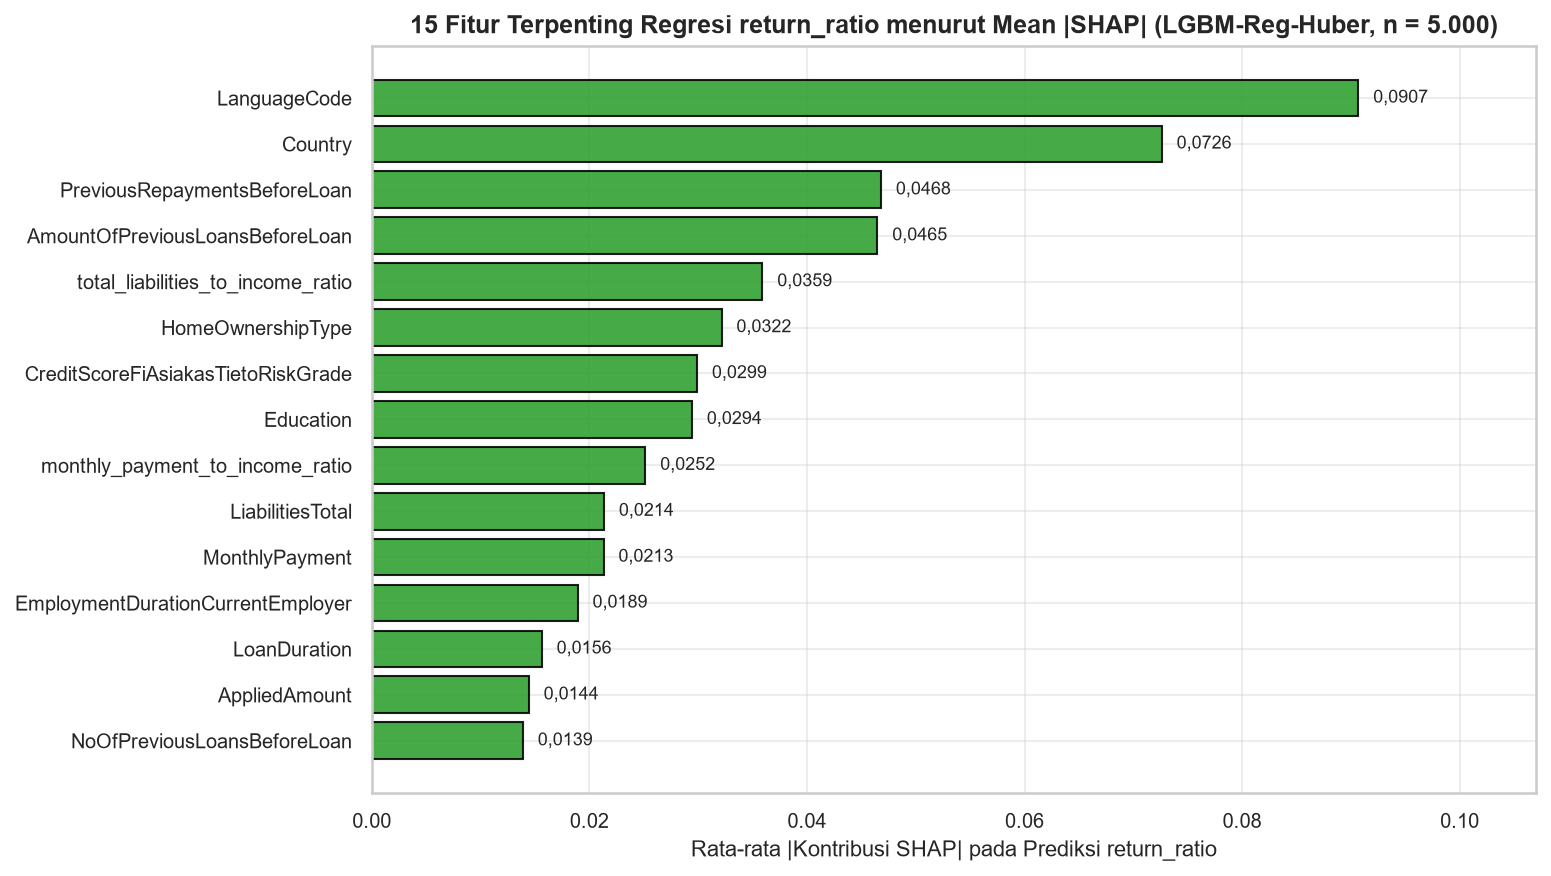

In [4]:
lift_reg_df = pd.read_csv(config.TABLES_DIR / "05_lift_by_decile.csv")
shap_reg_df = pd.read_csv(config.TABLES_DIR / "05_shap_top15.csv")

print("=== Tabel Lift 10 Desil Prediksi return_ratio pada Data Uji (LGBM-Reg-Huber) ===")
display(lift_reg_df)

print("\n=== 15 Fitur Terpenting Model Regresi Utama (LGBM-Reg-Huber) menurut Mean |SHAP| ===")
display(shap_reg_df)

display(Image(filename=str(config.FIGURES_DIR / "05_shap_top15_regression.png")))

## 4. Verifikasi Tabel Prediksi Regresi (`data/processed/predictions_return_ratio.parquet`)

Tabel prediksi regresi menyimpan seluruh `113.560` baris populasi `is_resolved == True` lengkap dengan `pred_return_ratio` (`LGBM-Reg-Huber`) dan `pred_baseline_group_median` (`Country × Rating`).

In [5]:
pred_reg_df = pd.read_parquet(config.DATA_PROCESSED / "predictions_return_ratio.parquet")
print(f"Shape predictions_return_ratio.parquet : {pred_reg_df.shape}")
print(f"LoanId unik                            : {pred_reg_df['LoanId'].is_unique}")
print(f"Jumlah NaN pada pred_return_ratio      : {int(pred_reg_df['pred_return_ratio'].isna().sum())}")

summary_reg_pred = pred_reg_df.groupby("split", as_index=False).agg(
    n=("LoanId", "count"),
    mean_actual=("return_ratio", "mean"),
    median_actual=("return_ratio", "median"),
    mean_pred_lgbm_huber=("pred_return_ratio", "mean"),
    mean_pred_baseline_cr=("pred_baseline_group_median", "mean"),
)
display(summary_reg_pred)
display(pred_reg_df.head(5))

Shape predictions_return_ratio.parquet : (113560, 14)


LoanId unik                            : True
Jumlah NaN pada pred_return_ratio      : 0


,split,n,mean_actual,median_actual,mean_pred_lgbm_huber,mean_pred_baseline_cr
0,test,34675,0.570775,0.391706,0.674561,0.899425
1,train,54103,0.913647,1.036649,0.902656,0.912795
2,val,24782,0.671976,0.577350,0.662009,0.872307


,LoanId,split,LoanDate,loan_year,Country,Rating,Amount,AppliedAmount,Interest,LoanDuration,default,return_ratio,pred_return_ratio,pred_baseline_group_median
0,66AE108B-532B-4BB3-BAB7-0019A46412C1,train,2016-03-23,2016,EE,C,2125.0,2125.0,20.97,60,1,1.015092,0.964862,1.102040
1,D152382E-A50D-46ED-8FF2-0053E0C86A70,train,2015-06-25,2015,EE,B,3000.0,3000.0,17.12,60,1,0.307887,1.186722,1.081106
2,87342E13-66CB-483F-833A-007953E50C78,train,2016-01-19,2016,EE,A,9100.0,10630.0,13.67,60,1,0.906096,1.266582,1.099925
3,87227056-6BF9-410C-98D1-008F788E122A,train,2015-03-27,2015,ES,F,1500.0,1500.0,40.40,60,1,0.547100,0.641067,0.793038
4,2DDE6336-E466-4624-A337-00A0ED1A1468,train,2015-12-22,2015,ES,HR,1090.0,1595.0,68.39,48,1,0.000009,0.419899,0.504132


## 5. Ringkasan Temuan Regresi & Sintesis untuk Tahap 5

1. **Peningkatan Signifikan atas Pembanding Naif & Skor Platform (`05_metrics_regression.csv`):** Model `LGBM-Reg-Huber` memangkas MAE data uji menjadi **`0,3902`** (dibanding `0,5323` pada median global dan `0,4697` pada median `Country × Rating`), menggeser $R^2$ dari sangat negatif (`-1,0242` dan `-0,4868`) menjadi positif (**`+0,0252`**), serta meningkatkan korelasi peringkat Spearman menjadi **$ho_s = 0,2881$** ($p < 10^{-300}$). Sebaliknya, `ExpectedReturn` Bondora memiliki korelasi peringkat negatif ($ho_s = -0,1651$) pada kohort uji yang telah *resolved*.
2. **Bias Level pada Uji & Anatomi Kesalahan Prediksi (`05_metrics_regression.csv`):** Rata-rata prediksi `LGBM-Reg-Huber` pada data uji cenderung terlalu tinggi (**rata-rata prediksi `0,6746` vs aktual `0,5708`**, selisih `+0,1038`; gunakan sebagai **urutan**). Karena model hanya menggunakan fitur saat pengajuan (*origination*) dan tidak mengetahui di muka pinjaman mana yang akan gagal bayar, prediksi model berada di rentang ekspektasi bersyarat (`mean_pred_default = 0,6253` vs `mean_actual_default = 0,2684`, MAE default `0,4026`; sedangkan `mean_pred_non_default = 0,7641` vs `mean_actual_non_default = 1,1201`, MAE non-default `0,3677`).
3. **Kegunaan Praktis di Tahap 5 (Prescriptive Analytics):** Walaupun level prediksi regresi cenderung lebih tinggi daripada rata-rata aktual uji (`0,6746` vs `0,5708`), **urutan peringkat `pred_return_ratio`** efektif mengidentifikasi segmen pinjaman dengan median pengembalian di atas `100%` pokok (**Desil 1** `median = 1,0405`, **Desil 2** `median = 1,0021`) sekaligus menghindari segmen penghancur modal (**Desil 8–10** dengan tingkat default `78%–79%` dan median pengembalian `< 0,26`). Pada **Tahap 5**, probabilitas gagal bayar terkalibrasi **`p_calibrated` (`LGBM-A`)** akan menjadi komponen utama pengukur risiko ($\hat{p}_i$), didampingi **`pred_return_ratio` (`LGBM-Reg-Huber`)** sebagai urutan pemeringkat kualitas sekunder.